# EDA

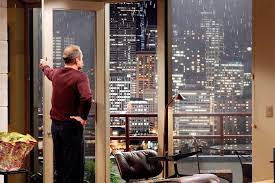

In [8]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore")

plt.rcParams.update(
    {"figure.figsize": (8, 5), "axes.facecolor": "white", "axes.edgecolor": "black"}
)
plt.rcParams["figure.facecolor"] = "w"
pd.plotting.register_matplotlib_converters()
pd.set_option("display.float_format", lambda x: "%.3f" % x)

In [9]:
df = pd.read_csv("data/eda.csv")

In [ ]:
# how big is the dataset?
df.shape

(21597, 21)

21597 = number of houses/rows
21    = number of variables/columns


In [12]:
# Look at the actual data
df.head()


,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,...,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,date,price
0,7129300520,3.000,1.000,1180.000,5650.000,1.000,NaN,0.000,3,7,...,0.000,1955,0.000,98178,47.511,-122.257,1340.000,5650.000,2014-10-13,221900.000
1,6414100192,3.000,2.250,2570.000,7242.000,2.000,0.000,0.000,3,7,...,400.000,1951,19910.000,98125,47.721,-122.319,1690.000,7639.000,2014-12-09,538000.000
2,5631500400,2.000,1.000,770.000,10000.000,1.000,0.000,0.000,3,6,...,0.000,1933,NaN,98028,47.738,-122.233,2720.000,8062.000,2015-02-25,180000.000
3,2487200875,4.000,3.000,1960.000,5000.000,1.000,0.000,0.000,5,7,...,910.000,1965,0.000,98136,47.521,-122.393,1360.000,5000.000,2014-12-09,604000.000
4,1954400510,3.000,2.000,1680.000,8080.000,1.000,0.000,0.000,3,8,...,0.000,1987,0.000,98074,47.617,-122.045,1800.000,7503.000,2015-02-18,510000.000


In [137]:
# Missing Data 
print("Shape:", df.shape)
print()
print("Missing values:")
print(df.isnull().sum())
print()
print("Waterfront unique values:", df["waterfront"].unique())
print()
print("yr_renovated unique values (first 20):", df["yr_renovated"].unique()[:20])

Shape: (21597, 25)

Missing values:
id                  0
bedrooms            0
bathrooms           0
sqft_living         0
sqft_lot            0
floors              0
waterfront          0
view               63
condition           0
grade               0
sqft_above          0
sqft_basement     452
yr_built            0
yr_renovated        0
zipcode             0
lat                 0
long                0
sqft_living15       0
sqft_lot15          0
date                0
price               0
is_renovated        0
renovation_age      0
house_age           0
grade_tier          0
dtype: int64

Waterfront unique values: [0. 1.]

yr_renovated unique values (first 20): [    0. 19910. 20020. 20100. 19920. 20130. 19940. 19780. 20050. 20030.
 19840. 19540. 20140. 20110. 19830. 19450. 19900. 19880. 19770. 19810.]


In [ ]:
# Data Quality Check
print("Total rows (sales records):", len(df))
print("Unique house IDs:", df["id"].nunique())
print("Duplicate ID rows:", df["id"].duplicated().sum())

# Get a deduplicated dataframe — keep only the most recent sale per house
df_unique = df.sort_values("date").drop_duplicates(subset="id", keep="last")
print("Deduplicated dataset size:", len(df_unique))

Total rows (sales records): 21597
Unique house IDs: 21420
Duplicate ID rows: 177
Deduplicated dataset size: 21420


In [ ]:
# Look at the missing data set in waterfront column
print(df["waterfront"].value_counts(dropna=False))
print()
print("Percent breakdown:")
print(df["waterfront"].value_counts(normalize=True, dropna=False) * 100)

waterfront
0.000    19060
NaN       2391
1.000      146
Name: count, dtype: int64

Percent breakdown:
waterfront
0.000   88.253
NaN     11.071
1.000    0.676
Name: proportion, dtype: float64


In [ ]:
# Replacing NAN values in waterfront column with 0
df["waterfront"] = df["waterfront"].fillna(0)

In [23]:
# Confirmation
print(df["waterfront"].value_counts(dropna=False))

waterfront
0.000    21451
1.000      146
Name: count, dtype: int64


In [25]:
# Look at the missing value in yr_renovated column
print(df["yr_renovated"].value_counts(dropna=False))
print()
print("Percent breakdown:")
print(df["yr_renovated"].value_counts(normalize=True, dropna=False) * 100)

yr_renovated
0.000        17005
NaN           3848
20140.000       73
20130.000       31
20030.000       31
             ...  
19760.000        1
19460.000        1
19590.000        1
19340.000        1
19440.000        1
Name: count, Length: 71, dtype: int64

Percent breakdown:
yr_renovated
0.000       78.738
NaN         17.817
20140.000    0.338
20130.000    0.144
20030.000    0.144
             ...  
19760.000    0.005
19460.000    0.005
19590.000    0.005
19340.000    0.005
19440.000    0.005
Name: proportion, Length: 71, dtype: float64


In [26]:
# Fill missing renovation years with 0 (assume not renovated)
df["yr_renovated"] = df["yr_renovated"].fillna(0)

# Create clean binary flag
df["is_renovated"] = df["yr_renovated"].apply(lambda x: 1 if x > 0 else 0)

# Confirm
print(df["is_renovated"].value_counts())

is_renovated
0    20853
1      744
Name: count, dtype: int64


In [27]:
# Check for missing values in grade column
print("Grade missing values:", df["grade"].isnull().sum())
print()
print(df["grade"].value_counts(dropna=False).sort_index())

Grade missing values: 0

grade
3        1
4       27
5      242
6     2038
7     8974
8     6065
9     2615
10    1134
11     399
12      89
13      13
Name: count, dtype: int64


In [28]:
# Define Jennifer's match criteria
jennifer_matches = df[
    (df["waterfront"] == 1) &
    (df["grade"] >= 10) &
    (df["is_renovated"] == 1) &
    (df["price"] >= df["price"].quantile(0.66))   # top third by price = "high budget"
]

print("Number of matching properties:", len(jennifer_matches))
jennifer_matches[["id","price","grade","waterfront","is_renovated","zipcode"]]

Number of matching properties: 6


,id,price,grade,waterfront,is_renovated,zipcode
2862,4114601570,3600000.000,10,1.000,1,98144
3910,9808700762,7060000.000,11,1.000,1,98004
8085,1924059029,4670000.000,12,1.000,1,98040
8775,3343302110,1800000.000,10,1.000,1,98006
15678,6117502230,1640000.000,12,1.000,1,98166
18185,3625059152,3300000.000,11,1.000,1,98008


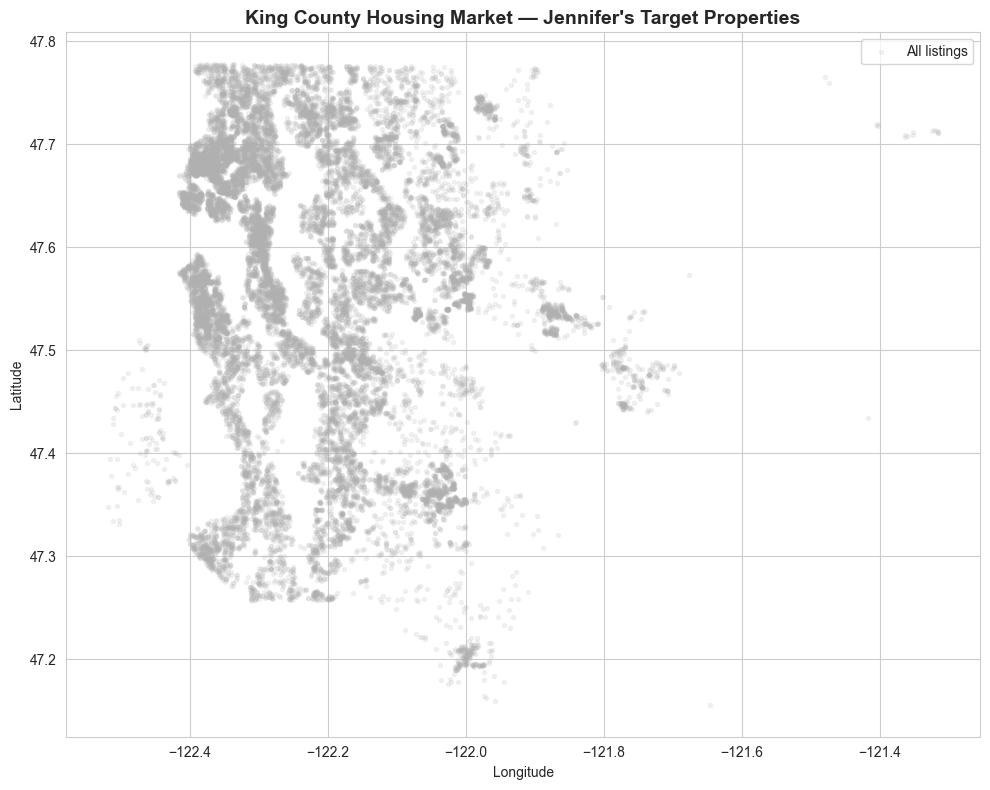

In [ ]:
# Sctatter data with all house listening
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.figure(figsize=(10,8))

plt.scatter(df["long"], df["lat"], alpha=0.15, color="#B0B0B0", s=8, label="All listings")


plt.title("King County Housing Market — Jennifer's Target Properties", fontsize=14, fontweight="bold")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.tight_layout()
plt.show()

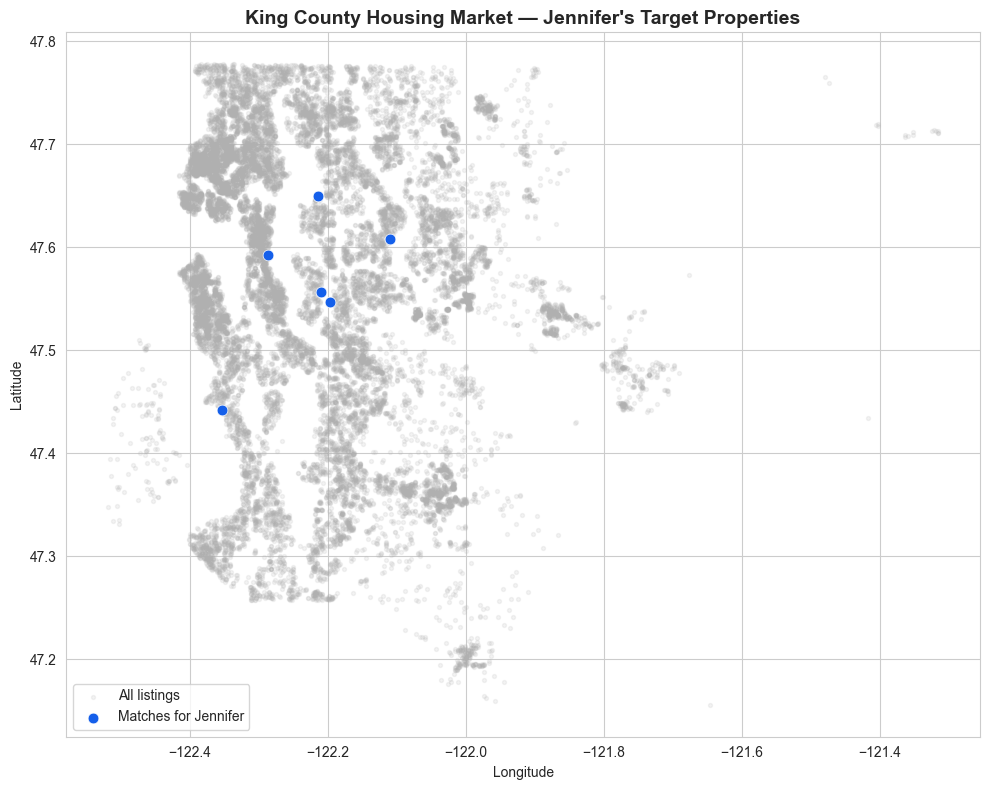

In [ ]:
# Scatter data with Jennifer's matches highlighted
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.figure(figsize=(10,8))

plt.scatter(df["long"], df["lat"], alpha=0.15, color="#B0B0B0", s=8, label="All listings")
plt.scatter(jennifer_matches["long"], jennifer_matches["lat"], 
            color="#145FEA", s=60, edgecolor="white", linewidth=0.5, label="Matches for Jennifer")

plt.title("King County Housing Market — Jennifer's Target Properties", fontsize=14, fontweight="bold")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Hypothesis 1: Does waterfront access have a significant relationship with residential property sale prices in King County?
# # statsitical test to compare the mean price of waterfront vs non-waterfront properties
from scipy import stats

group_water = df[df["waterfront"] == 1]["price"]
group_nowater = df[df["waterfront"] == 0]["price"]

t_stat, p_val = stats.ttest_ind(group_water, group_nowater, equal_var=False)

print("Waterfront mean price: ${:,.0f}".format(group_water.mean()))
print("Non-waterfront mean price: ${:,.0f}".format(group_nowater.mean()))
print("Price difference: ${:,.0f}".format(group_water.mean() - group_nowater.mean()))
print("t-statistic:", round(t_stat, 3))
print("p-value:", p_val)

Waterfront mean price: $1,717,215
Non-waterfront mean price: $532,286
Price difference: $1,184,929
t-statistic: 12.496
p-value: 8.67996514659156e-25


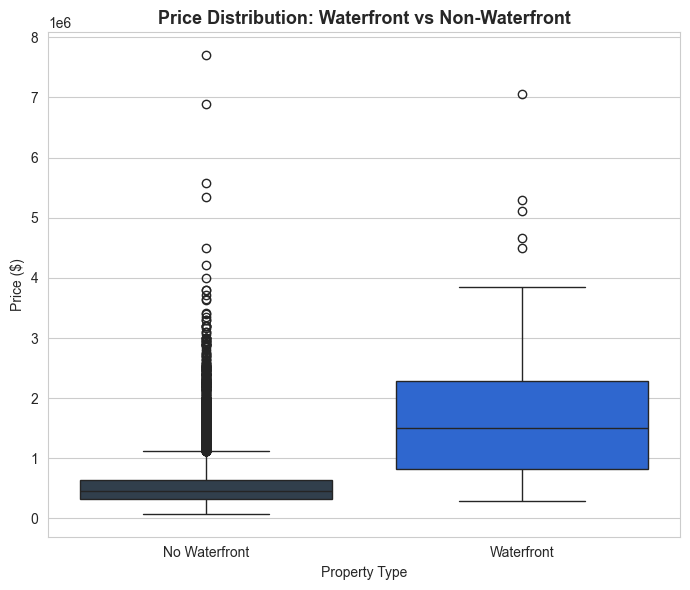

In [ ]:
# Hypothesis 1: Does waterfront access have a significant relationship with residential property sale prices in King County?
# # Plot the price distribution for waterfront vs non-waterfront properties
plt.figure(figsize=(7,6))
sns.boxplot(data=df, x="waterfront", y="price", palette=["#2C3F51","#145fea"])
plt.xticks([0,1], ["No Waterfront", "Waterfront"])
plt.title("Price Distribution: Waterfront vs Non-Waterfront", fontsize=13, fontweight="bold")
plt.xlabel("Property Type")
plt.ylabel("Price ($)")
plt.tight_layout()
plt.show()

In [76]:
# Hypothesis 1: Does waterfront access have a significant relationship with residential property sale prices in King County?
# # statsitical test to compare the mean price of waterfront vs non-waterfront properties
from scipy import stats

group_water = df[df["waterfront"] == 1]["price"]
group_nowater = df[df["waterfront"] == 0]["price"]

t_stat, p_val = stats.ttest_ind(group_water, group_nowater, equal_var=False)

print("Waterfront mean price: ${:,.0f}".format(group_water.mean()))
print("Non-waterfront mean price: ${:,.0f}".format(group_nowater.mean()))
print("Price difference: ${:,.0f}".format(group_water.mean() - group_nowater.mean()))
print("t-statistic:", round(t_stat, 3))
print("p-value:", p_val)

Waterfront mean price: $1,717,215
Non-waterfront mean price: $532,286
Price difference: $1,184,929
t-statistic: 12.496
p-value: 8.67996514659156e-25


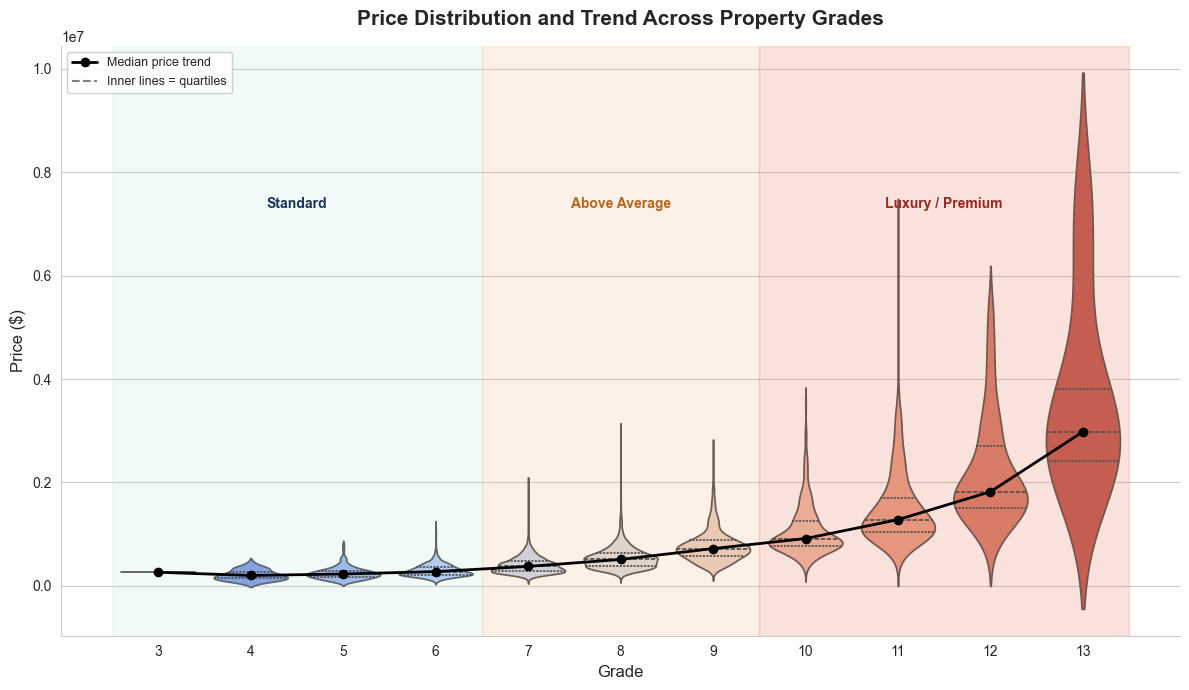

In [62]:
# Hypothesis 2: Is there a correlation between property grade and sale price in King County?
plt.figure(figsize=(12,7))
sns.set_style("whitegrid")

grade_order = sorted(df["grade"].unique())
x_positions = list(range(len(grade_order)))

# Violin plot
sns.violinplot(data=df, x="grade", y="price", palette="coolwarm", inner="quartile", order=grade_order)

# Median trend line
medians = df.groupby("grade")["price"].median()
plt.plot(x_positions, [medians[g] for g in grade_order], 
         color="black", marker="o", markersize=6, linewidth=2, zorder=10)

# --- Grading tier background shading ---
def grade_to_x(g):
    return grade_order.index(g)

plt.axvspan(grade_to_x(3)-0.5, grade_to_x(6)+0.5, color="#A8DADC", alpha=0.15)
plt.axvspan(grade_to_x(7)-0.5, grade_to_x(9)+0.5, color="#F4A261", alpha=0.15)
plt.axvspan(grade_to_x(10)-0.5, grade_to_x(13)+0.5, color="#E76F51", alpha=0.20)

ymax = df["price"].max()
plt.text((grade_to_x(3)+grade_to_x(6))/2, ymax*0.95, "Standard", ha="center", fontsize=10, fontweight="bold", color="#1D3557")
plt.text((grade_to_x(7)+grade_to_x(9))/2, ymax*0.95, "Above Average", ha="center", fontsize=10, fontweight="bold", color="#B5651D")
plt.text((grade_to_x(10)+grade_to_x(13))/2, ymax*0.95, "Luxury / Premium", ha="center", fontsize=10, fontweight="bold", color="#9D2822")

plt.title("Price Distribution and Trend Across Property Grades", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Grade", fontsize=12)
plt.ylabel("Price ($)", fontsize=12)

plt.legend(
    handles=[plt.Line2D([0], [0], color="black", marker="o", linewidth=2, label="Median price trend"),
             plt.Line2D([0], [0], color="gray", linestyle="--", label="Inner lines = quartiles")],
    loc="upper left", fontsize=9, framealpha=0.9
)

plt.gca().spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

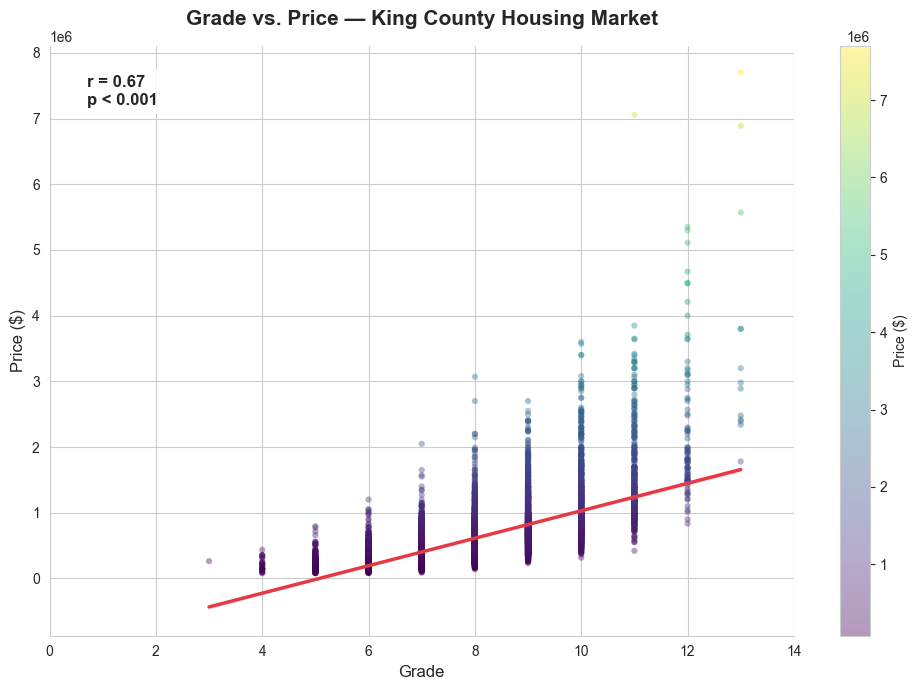

In [55]:
# Hypothesis 2: Is the overall property grade associated with residential property sale prices?
plt.figure(figsize=(10,7))
sns.set_style("whitegrid")

scatter = plt.scatter(df["grade"], df["price"], 
                       c=df["price"], cmap="viridis", 
                       alpha=0.4, s=20, edgecolor="none")

sns.regplot(data=df, x="grade", y="price", scatter=False, 
            line_kws={"color":"#E63946", "linewidth":2.5})

plt.colorbar(scatter, label="Price ($)")
plt.title("Grade vs. Price — King County Housing Market", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Grade", fontsize=12)
plt.ylabel("Price ($)", fontsize=12)
plt.xticks(range(0, 15, 2))
plt.xlim(0, 14)

# Annotate correlation directly on the chart
from scipy import stats
r, p = stats.pearsonr(df["grade"], df["price"])
plt.annotate(f"r = {r:.2f}\np < 0.001", xy=(0.05, 0.9), xycoords="axes fraction",
             fontsize=12, fontweight="bold", bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

plt.gca().spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

In [ ]:
# Determine the correlation coefficient and p-value for grade vs price
from scipy import stats

correlation, p_val = stats.pearsonr(df["grade"], df["price"])

print("Correlation coefficient (r):", round(correlation, 4))
print("p-value:", p_val)

Correlation coefficient (r): 0.668
p-value: 0.0


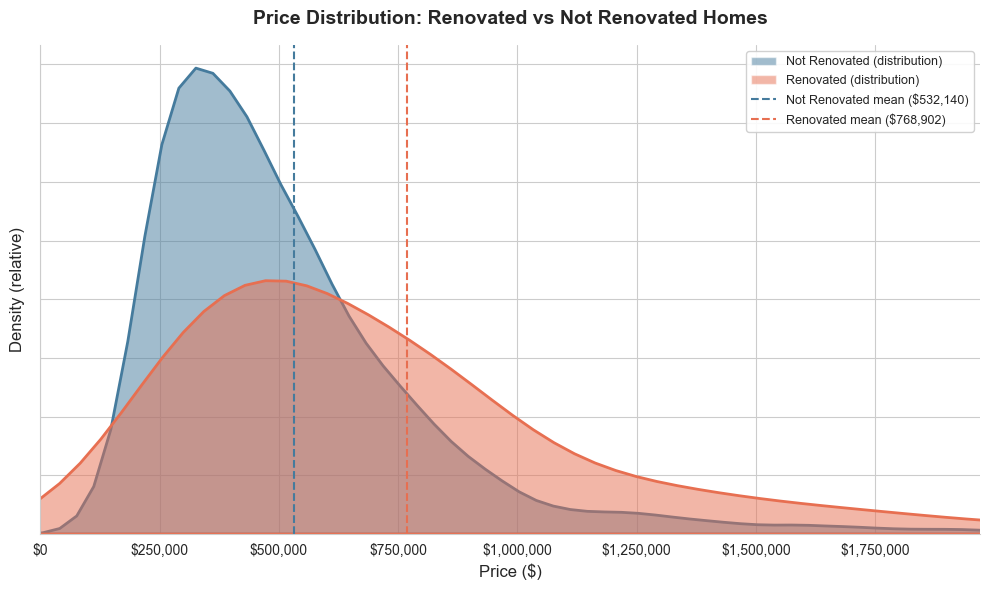

In [ ]:

# Hypothesis 3: Does property renovation status have a significant relationship with residential property sale prices?
import matplotlib.ticker as ticker

plt.figure(figsize=(10,6))
sns.set_style("whitegrid")

sns.kdeplot(data=df[df["is_renovated"]==0]["price"], fill=True, color="#457B9D", 
            alpha=0.5, linewidth=2, label="Not Renovated")
sns.kdeplot(data=df[df["is_renovated"]==1]["price"], fill=True, color="#E76F51", 
            alpha=0.5, linewidth=2, label="Renovated")

mean_noreno = df[df["is_renovated"]==0]["price"].mean()
mean_reno = df[df["is_renovated"]==1]["price"].mean()

plt.axvline(mean_noreno, color="#457B9D", linestyle="--", linewidth=1.5)
plt.axvline(mean_reno, color="#E76F51", linestyle="--", linewidth=1.5)

plt.title("Price Distribution: Renovated vs Not Renovated Homes", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Price ($)", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.xlim(0, df["price"].quantile(0.99))

# Fix x-axis: show real dollar values, no scientific notation
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'${x:,.0f}'))

# Fix y-axis: hide the tiny numbers entirely (density values aren't meaningful to a client anyway)
plt.gca().set_yticklabels([])
plt.ylabel("Density (relative)", fontsize=12)

legend_elements = [
    plt.Rectangle((0,0),1,1, facecolor="#457B9D", alpha=0.5, label="Not Renovated (distribution)"),
    plt.Rectangle((0,0),1,1, facecolor="#E76F51", alpha=0.5, label="Renovated (distribution)"),
    plt.Line2D([0],[0], color="#457B9D", linestyle="--", linewidth=1.5, label=f"Not Renovated mean (${mean_noreno:,.0f})"),
    plt.Line2D([0],[0], color="#E76F51", linestyle="--", linewidth=1.5, label=f"Renovated mean (${mean_reno:,.0f})"),
]
plt.legend(handles=legend_elements, fontsize=9, loc="upper right", framealpha=0.9)

plt.gca().spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

In [70]:
# Hypothesis 3: Does property renovation status have a significant relationship with residential property sale prices?
# Recently vs old renovation age (years since renovation) vs price
df["renovation_age"] = 2015 - df["yr_renovated"]  # dataset covers sales through 2015
renovated_only = df[df["is_renovated"]==1]

correlation, p_val = stats.pearsonr(renovated_only["renovation_age"], renovated_only["price"])
print("Correlation (years since renovation vs price):", correlation, "| p-value:", p_val)

Correlation (years since renovation vs price): -0.12549911691343754 | p-value: 0.0006014106988534724


In [ ]:

# Hypothesis 3: Does property renovation status have a significant relationship with residential property sale prices?
# # statistical difference between mean price of renovated vs non-renovated properties
group_reno = df[df["is_renovated"] == 1]["price"]
group_noreno = df[df["is_renovated"] == 0]["price"]

t_stat, p_val = stats.ttest_ind(group_reno, group_noreno, equal_var=False)

print("Renovated mean price: ${:,.0f}".format(group_reno.mean()))
print("Not renovated mean price: ${:,.0f}".format(group_noreno.mean()))
print("Price difference: ${:,.0f}".format(group_reno.mean() - group_noreno.mean()))
print("t-statistic:", round(t_stat, 3))
print("p-value:", p_val)

Renovated mean price: $768,902
Not renovated mean price: $532,140
Price difference: $236,762
t-statistic: 10.24
p-value: 3.8416184814146096e-23


Multivariat model

In [77]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [79]:
import statsmodels.api as sm
print(df[["waterfront", "sqft_living", "grade", "condition", 
          "bathrooms", "bedrooms", "floors", "is_renovated", "view", "house_age"]].isnull().sum())

waterfront       0
sqft_living      0
grade            0
condition        0
bathrooms        0
bedrooms         0
floors           0
is_renovated     0
view            63
house_age        0
dtype: int64


In [ ]:
# determine number of Jennifer's matches in 10-13 grade, renovated and waterrfront houses
all_houses = df.copy()

high_grade = df[df["grade"] >= 10]

high_grade_reno = high_grade[high_grade["is_renovated"] == 1]

high_grade_reno_water = high_grade_reno[high_grade_reno["waterfront"] == 1]


high_grade_reno_nowater = high_grade_reno[high_grade_reno["waterfront"] == 0]

print("All houses:", len(all_houses))
print("High grade (10-13):", len(high_grade))
print("High grade + Renovated:", len(high_grade_reno))
print("High grade + Renovated + Waterfront:", len(high_grade_reno_water))
print("High grade + Renovated, NO waterfront:", len(high_grade_reno_nowater))

All houses: 21597
High grade (10-13): 1635
High grade + Renovated: 59
High grade + Renovated + Waterfront: 6
High grade + Renovated, NO waterfront: 53


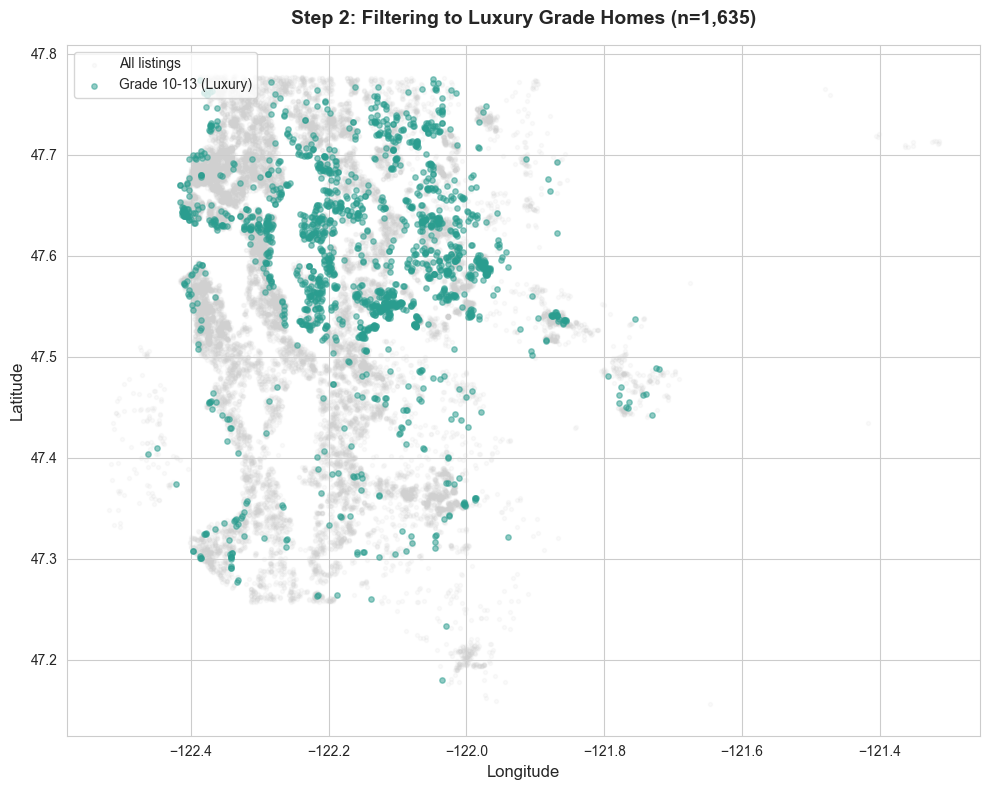

In [ ]:
# plot the geographic distribution of all houses vs high grade houses
plt.figure(figsize=(10,8))

plt.scatter(all_houses["long"], all_houses["lat"], alpha=0.1, color="#D0D0D0", s=8, label="All listings")
plt.scatter(high_grade["long"], high_grade["lat"], alpha=0.5, color="#2A9D8F", s=15, label="Grade 10-13 (Luxury)")

plt.title(f"Step 2: Filtering to Luxury Grade Homes (n={len(high_grade):,})", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Longitude", fontsize=12)
plt.ylabel("Latitude", fontsize=12)
plt.legend(fontsize=10, loc="upper left")
plt.tight_layout()
plt.show()

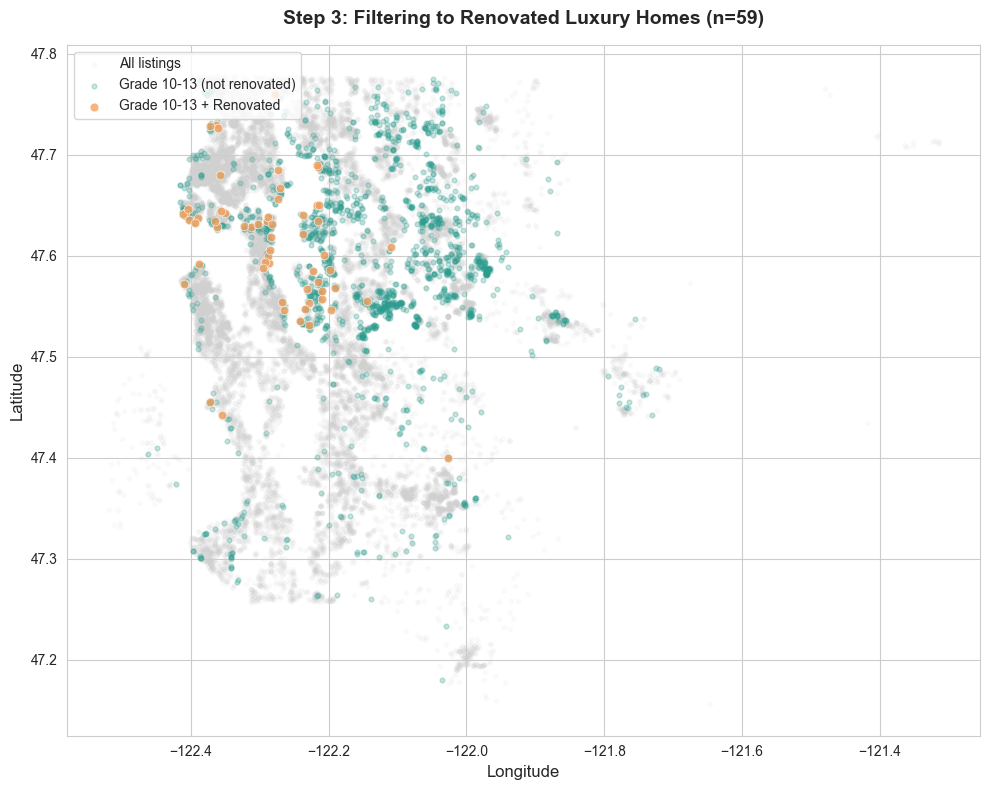

In [ ]:
#scatter plot of all houses vs high grade + renovated 
plt.figure(figsize=(10,8))

plt.scatter(all_houses["long"], all_houses["lat"], alpha=0.08, color="#D0D0D0", s=8, label="All listings")
plt.scatter(high_grade["long"], high_grade["lat"], alpha=0.25, color="#2A9D8F", s=12, label="Grade 10-13 (not renovated)")
plt.scatter(high_grade_reno["long"], high_grade_reno["lat"], alpha=0.8, color="#F4A261", s=40, 
            edgecolor="white", linewidth=0.5, label="Grade 10-13 + Renovated")

plt.title(f"Step 3: Filtering to Renovated Luxury Homes (n={len(high_grade_reno):,})", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Longitude", fontsize=12)
plt.ylabel("Latitude", fontsize=12)
plt.legend(fontsize=10, loc="upper left")
plt.tight_layout()
plt.show()

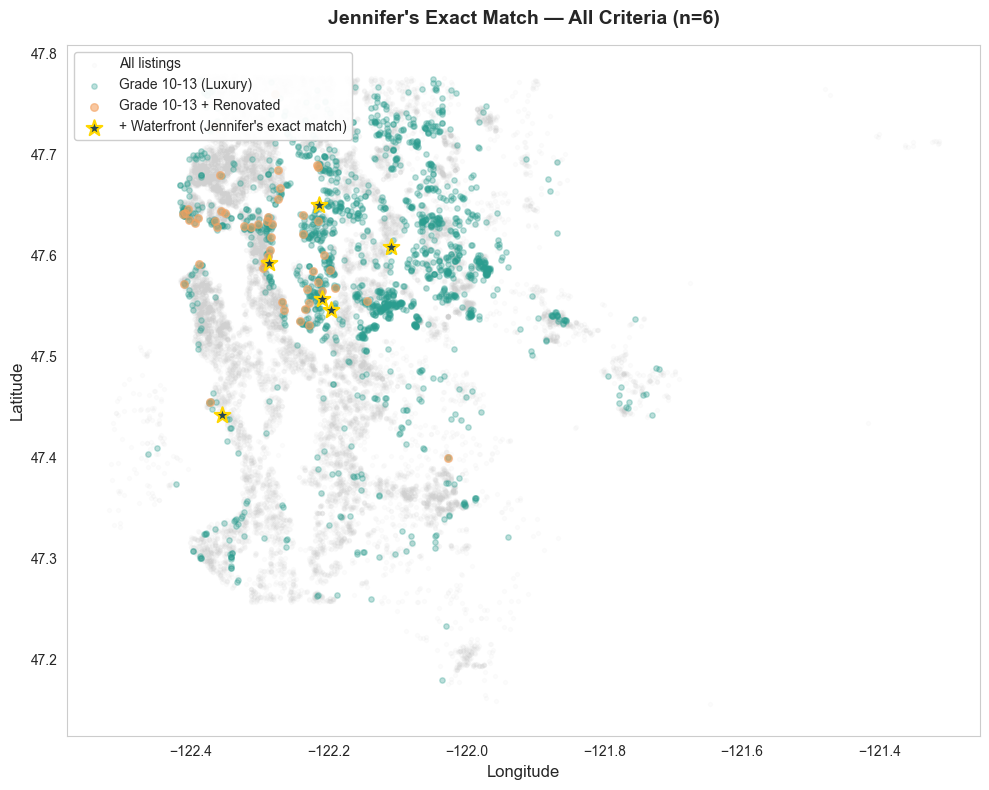

In [ ]:
# Scatter data with 10-13 grade, renovated and waterfront homes highlighted
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))

# Layer 1: All listings (background)
plt.scatter(all_houses["long"], all_houses["lat"], alpha=0.06, color="#D0D0D0", s=8, label="All listings")

# Layer 2: Grade 10-13 only
plt.scatter(high_grade["long"], high_grade["lat"], alpha=0.3, color="#2A9D8F", s=15, label="Grade 10-13 (Luxury)")

# Layer 3: Grade 10-13 + Renovated
plt.scatter(high_grade_reno["long"], high_grade_reno["lat"], alpha=0.6, color="#F4A261", s=30, label="Grade 10-13 + Renovated")

# Layer 4: Grade 10-13 + Renovated + Waterfront (final match)
plt.scatter(high_grade_reno_water["long"], high_grade_reno_water["lat"], color="#264653", s=140,
            marker="*", edgecolor="gold", linewidth=1.5, label="+ Waterfront (Jennifer's exact match)", zorder=10)

plt.title(f"Jennifer's Exact Match — All Criteria (n={len(high_grade_reno_water):,})",
          fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Longitude", fontsize=12)
plt.ylabel("Latitude", fontsize=12)
plt.legend(fontsize=10, loc="upper left", framealpha=0.95)

# Remove background gridlines
plt.grid(False)
ax = plt.gca()
ax.set_facecolor("white")

plt.tight_layout()
plt.show()

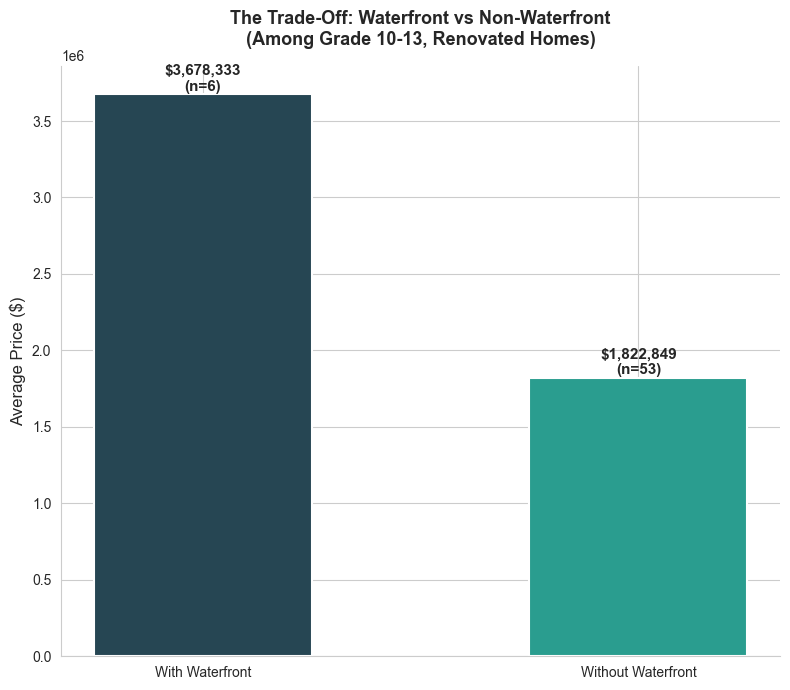

In [ ]:
# Trade-off: Waterfront vs Non-Waterfront (among Grade 10-13, Renovated Homes)
plt.figure(figsize=(8,7))

comparison_data = pd.DataFrame({
    "Group": ["With Waterfront", "Without Waterfront"],
    "Mean Price": [high_grade_reno_water["price"].mean(), high_grade_reno_nowater["price"].mean()],
    "Count": [len(high_grade_reno_water), len(high_grade_reno_nowater)]
})

bars = plt.bar(comparison_data["Group"], comparison_data["Mean Price"], 
                color=["#264653", "#2A9D8F"], edgecolor="white", linewidth=1.5, width=0.5)

for bar, price, count in zip(bars, comparison_data["Mean Price"], comparison_data["Count"]):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20000, 
              f"${price:,.0f}\n(n={count})", ha="center", fontsize=11, fontweight="bold")

plt.title("The Trade-Off: Waterfront vs Non-Waterfront\n(Among Grade 10-13, Renovated Homes)", 
           fontsize=13, fontweight="bold", pad=15)
plt.ylabel("Average Price ($)", fontsize=12)
plt.xlabel("")
plt.gca().spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

In [86]:
# Extract full details for the 6 exact-match properties (Grade 10-13 + Renovated + Waterfront)
jennifer_final_matches = df[
    (df["grade"] >= 10) &
    (df["is_renovated"] == 1) &
    (df["waterfront"] == 1)
]

print("Number of matching properties:", len(jennifer_final_matches))

# Display all columns, sorted by price (highest first, or change to ascending if preferred)
jennifer_final_matches_display = jennifer_final_matches.sort_values("price", ascending=False)
jennifer_final_matches_display

Number of matching properties: 6


,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,...,zipcode,lat,long,sqft_living15,sqft_lot15,date,price,is_renovated,renovation_age,house_age
3910,9808700762,5.000,4.500,10040.000,37325.000,2.000,1.000,2.000,3,11,...,98004,47.650,-122.214,3930.000,25449.000,2014-06-11,7060000.000,1,-17995.000,75
8085,1924059029,5.000,6.750,9640.000,13068.000,1.000,1.000,4.000,3,12,...,98040,47.557,-122.210,3270.000,10454.000,2014-06-17,4670000.000,1,-18075.000,32
2862,4114601570,3.000,3.250,5020.000,12431.000,2.000,1.000,4.000,3,10,...,98144,47.593,-122.287,3680.000,12620.000,2014-11-18,3600000.000,1,-18005.000,74
18185,3625059152,3.000,3.250,4220.000,41300.000,1.000,1.000,4.000,4,11,...,98008,47.608,-122.110,3810.000,30401.000,2014-12-30,3300000.000,1,-17855.000,57
8775,3343302110,3.000,3.000,2790.000,13295.000,2.000,1.000,4.000,4,10,...,98006,47.547,-122.197,3140.000,11949.000,2015-03-06,1800000.000,1,-17875.000,82
15678,6117502230,3.000,3.500,4660.000,21164.000,2.000,1.000,4.000,3,12,...,98166,47.442,-122.354,3140.000,24274.000,2014-12-01,1640000.000,1,-17885.000,40


In [91]:
jennifer_final_matches_display.to_csv("jennifer_matched_properties.csv", index=False)
print("Saved to jennifer_matched_properties.csv")

Saved to jennifer_matched_properties.csv


In [ ]:
# comparison of key variables between waterfront and non-waterfront properties (among Grade 10-13, Renovated Homes)

comparison_vars = ["price", "sqft_living", "sqft_lot", "bedrooms", "bathrooms", 
                    "floors", "condition", "view", "sqft_above", "sqft_basement", 
                    "yr_built", "grade"]

comparison_table = pd.DataFrame({
    "With Waterfront": high_grade_reno_water[comparison_vars].mean(),
    "Without Waterfront": high_grade_reno_nowater[comparison_vars].mean()
})

comparison_table["Difference"] = comparison_table["With Waterfront"] - comparison_table["Without Waterfront"]
comparison_table["% Difference"] = (comparison_table["Difference"] / comparison_table["Without Waterfront"]) * 100

comparison_table = comparison_table.round(1)

print("Group sizes — With Waterfront: {} | Without Waterfront: {}".format(
    len(high_grade_reno_water), len(high_grade_reno_nowater)))
comparison_table

Group sizes — With Waterfront: 6 | Without Waterfront: 53


,With Waterfront,Without Waterfront,Difference,% Difference
price,3678333.300,1822849.100,1855484.300,101.800
sqft_living,6061.700,3976.200,2085.400,52.400
sqft_lot,23097.200,14172.600,8924.600,63.000
bedrooms,3.700,4.200,-0.500,-12.100
bathrooms,4.000,3.400,0.700,19.500
floors,1.700,1.900,-0.300,-13.400
condition,3.300,3.200,0.100,2.700
view,3.700,1.500,2.100,141.400
sqft_above,4235.000,3107.500,1127.500,36.300
sqft_basement,1826.700,837.600,989.000,118.100


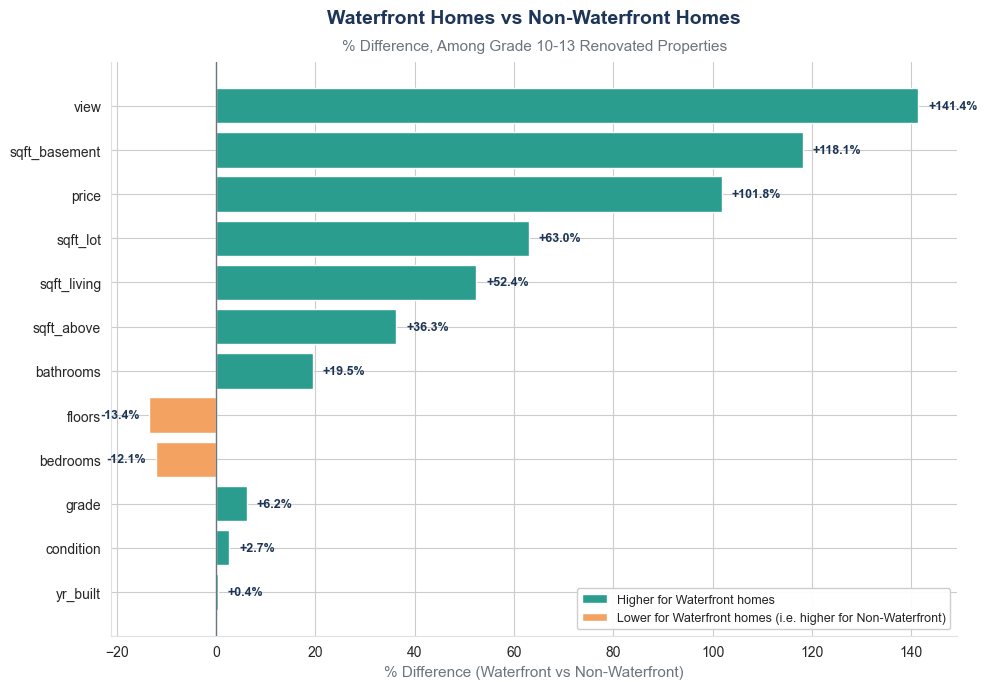

In [ ]:
# pllot the % difference for each variable, sorted by absolute value of % difference

plt.figure(figsize=(10,7))


sorted_table = comparison_table.reindex(comparison_table["% Difference"].abs().sort_values(ascending=True).index)

colors = ["#2A9D8F" if x >= 0 else "#F4A261" for x in sorted_table["% Difference"]]

bars = plt.barh(sorted_table.index, sorted_table["% Difference"], color=colors, edgecolor="white", linewidth=1)

plt.axvline(0, color="#6C757D", linewidth=1)

plt.title("Waterfront Homes vs Non-Waterfront Homes", fontsize=14, fontweight="bold", color="#1D3557", pad=28)
plt.gcf().text(0.54, 0.92, "% Difference, Among Grade 10-13 Renovated Properties", 
               fontsize=11, color="#6C757D", ha="center")

plt.xlabel("% Difference (Waterfront vs Non-Waterfront)", fontsize=11, color="#6C757D")
plt.ylabel("")


for i, (idx, val) in enumerate(zip(sorted_table.index, sorted_table["% Difference"])):
    plt.text(val + (2 if val >= 0 else -2), i, f"{val:+.1f}%", 
              va="center", ha="left" if val >= 0 else "right", fontsize=9, fontweight="bold", color="#1D3557")


legend_elements = [
    plt.Rectangle((0,0),1,1, facecolor="#2A9D8F", label="Higher for Waterfront homes"),
    plt.Rectangle((0,0),1,1, facecolor="#F4A261", label="Lower for Waterfront homes (i.e. higher for Non-Waterfront)"),
]
plt.legend(handles=legend_elements, fontsize=9, loc="lower right", framealpha=0.95)

plt.gca().spines[['top','right']].set_visible(False)
plt.gca().spines['bottom'].set_color('#DEE2E6')
plt.gca().spines['left'].set_color('#DEE2E6')
plt.tight_layout()
plt.show()

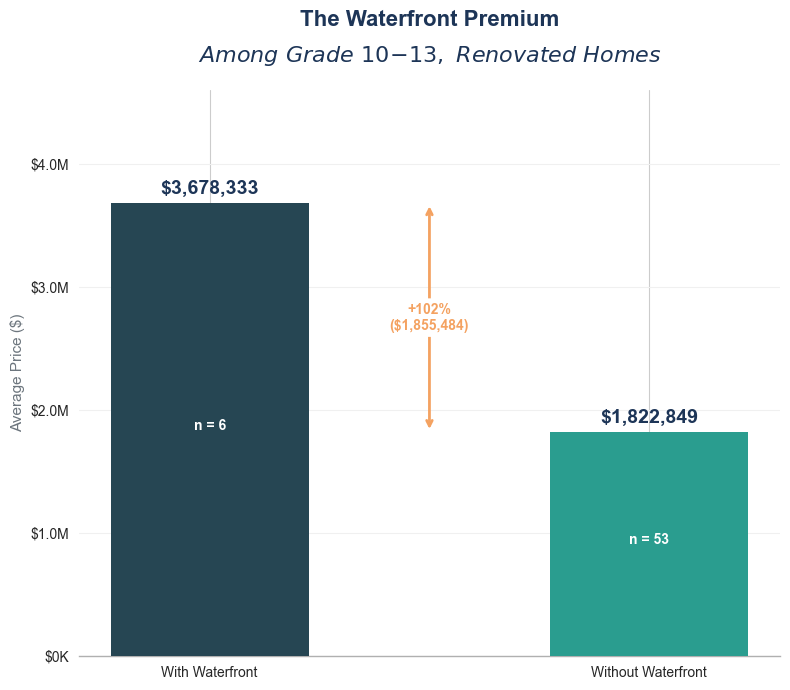

In [ ]:
# plot the average price for waterfront vs non-waterfront properties (among Grade 10-13, Renovated Homes)

fig, ax = plt.subplots(figsize=(8,7))

groups = ["With Waterfront", "Without Waterfront"]
prices = [high_grade_reno_water["price"].mean(), high_grade_reno_nowater["price"].mean()]
counts = [len(high_grade_reno_water), len(high_grade_reno_nowater)]
colors = ["#264653", "#2A9D8F"]
x_pos = [0, 1]

bars = ax.bar(x_pos, prices, color=colors, width=0.45, edgecolor="none", zorder=3)
ax.set_xticks(x_pos)
ax.set_xticklabels(groups, fontsize=11)


for bar, price, count in zip(bars, prices, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + (max(prices)*0.02),
            f"${price:,.0f}", ha="center", fontsize=14, fontweight="bold", color="#1D3557")
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 0.5,
            f"n = {count}", ha="center", fontsize=10, color="white", fontweight="bold")


diff = prices[0] - prices[1]
pct = (diff / prices[1]) * 100
gap_x = 0.5
ax.annotate('', xy=(gap_x, prices[1]), xytext=(gap_x, prices[0]),
            arrowprops=dict(arrowstyle='<->', color="#F4A261", lw=2))
ax.text(gap_x, (prices[0]+prices[1])/2, f"+{pct:.0f}%\n(${diff:,.0f})",
        fontsize=10, fontweight="bold", color="#F4A261", va="center", ha="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="none"))


ax.set_title("The Waterfront Premium\n" + r"$\it{Among\ Grade\ 10\!-\!13,\ Renovated\ Homes}$", 
              fontsize=16, fontweight="bold", color="#1D3557", pad=20, linespacing=1.8)


ax.set_ylabel("Average Price ($)", fontsize=11, color="#6C757D")
ax.set_ylim(0, max(prices) * 1.25)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#B0B0B0')
ax.spines['bottom'].set_linewidth(1)
ax.tick_params(left=False, labelsize=10)
ax.yaxis.grid(True, color="#F0F0F0", zorder=0)
ax.set_axisbelow(True)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'${x/1e6:.1f}M' if x >= 1e6 else f'${x/1e3:.0f}K'))

plt.tight_layout()
plt.show()

In [ ]:
# determine the average price per square foot for waterfront vs non-waterfront properties (among Grade 10-13, Renovated Homes)
high_grade_reno_water_copy = high_grade_reno_water.copy()
high_grade_reno_nowater_copy = high_grade_reno_nowater.copy()

high_grade_reno_water_copy["price_per_sqft"] = high_grade_reno_water_copy["price"] / high_grade_reno_water_copy["sqft_living"]
high_grade_reno_nowater_copy["price_per_sqft"] = high_grade_reno_nowater_copy["price"] / high_grade_reno_nowater_copy["sqft_living"]

print("With waterfront - avg $/sqft:", round(high_grade_reno_water_copy["price_per_sqft"].mean(), 2))
print("Without waterfront - avg $/sqft:", round(high_grade_reno_nowater_copy["price_per_sqft"].mean(), 2))

With waterfront - avg $/sqft: 613.97
Without waterfront - avg $/sqft: 455.76


In [ ]:
# determine the average values for each variable for waterfront vs non-waterfront properties (among Grade 10-13, Renovated Homes)
gain_vars = ["sqft_living", "bedrooms", "bathrooms", "sqft_lot", "sqft_above"]

gains = pd.DataFrame({
    "With Waterfront (avg)": high_grade_reno_water[gain_vars].mean(),
    "Without Waterfront (avg)": high_grade_reno_nowater[gain_vars].mean(),
})
gains["Extra if she drops waterfront"] = gains["Without Waterfront (avg)"] - gains["With Waterfront (avg)"]
gains.round(1)

,With Waterfront (avg),Without Waterfront (avg),Extra if she drops waterfront
sqft_living,6061.700,3976.200,-2085.400
bedrooms,3.700,4.200,0.500
bathrooms,4.000,3.400,-0.700
sqft_lot,23097.200,14172.600,-8924.600
sqft_above,4235.000,3107.500,-1127.500


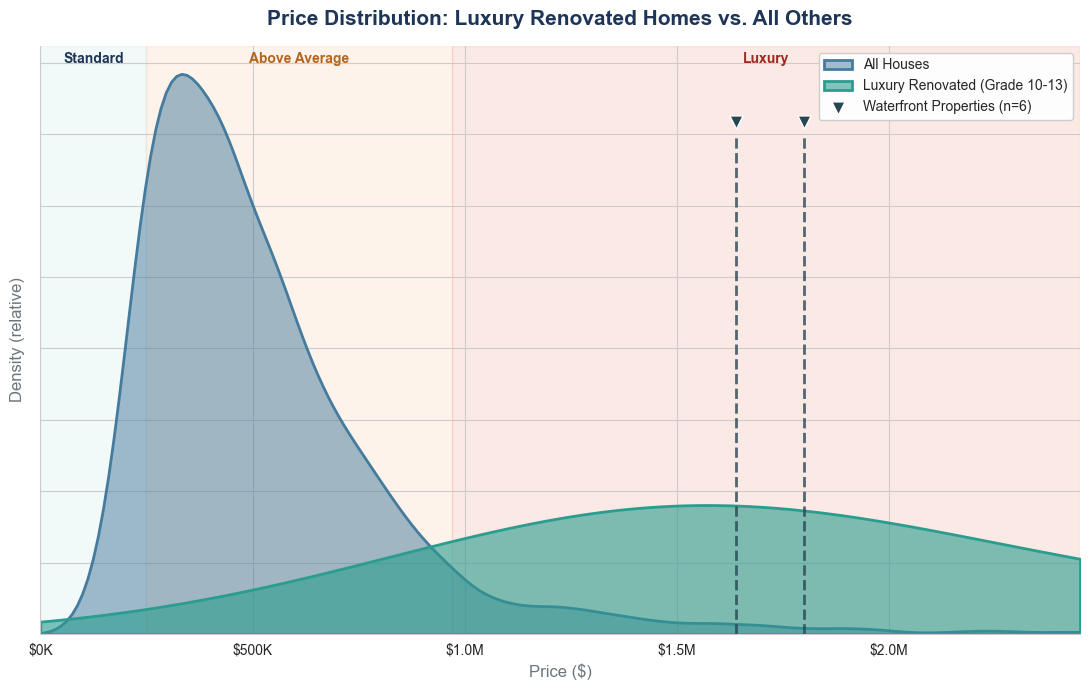

In [ ]:
# Plot the price distribution for all houses vs luxury renovated homes (grade 10-13, renovated) and highlight waterfront properties


fig, ax = plt.subplots(figsize=(11,7))
sns.set_style("whitegrid")


All_houses = df[~((df["grade"]>=10) & (df["is_renovated"]==1))]
luxury_renovated = df[(df["grade"]>=10) & (df["is_renovated"]==1)]
luxury_renovated_waterfront = luxury_renovated[luxury_renovated["waterfront"]==1]

standard_cutoff = df["price"].quantile(0.107)  
luxury_cutoff = df["price"].quantile(0.924)    
xmax = df["price"].quantile(0.995)

ax.axvspan(0, standard_cutoff, color="#A8DADC", alpha=0.15, zorder=0)
ax.axvspan(standard_cutoff, luxury_cutoff, color="#F4A261", alpha=0.12, zorder=0)
ax.axvspan(luxury_cutoff, xmax, color="#E76F51", alpha=0.15, zorder=0)

ax.text(standard_cutoff/2, ax.get_ylim()[1], "", zorder=0)  

# --- KDE curves ---
sns.kdeplot(All_houses["price"], fill=True, color="#457B9D", alpha=0.5, 
            linewidth=2, label="All Houses", ax=ax, clip=(0, xmax))
sns.kdeplot(luxury_renovated["price"], fill=True, color="#2A9D8F", alpha=0.6, 
            linewidth=2, label="Luxury Renovated (Grade 10-13)", ax=ax, clip=(0, xmax))


ymax = ax.get_ylim()[1]
for price in luxury_renovated_waterfront["price"]:
    ax.axvline(price, color="#264653", linewidth=2, linestyle="--", alpha=0.8, ymax=0.85)
ax.scatter(luxury_renovated_waterfront["price"], [ymax*0.87]*len(luxury_renovated_waterfront), 
           marker="v", s=90, color="#264653", edgecolor="white", linewidth=1, zorder=10,
           label="Waterfront Properties (n=6)")


ax.text(standard_cutoff*0.5, ymax*0.97, "Standard", ha="center", fontsize=10, fontweight="bold", color="#1D3557")
ax.text((standard_cutoff+luxury_cutoff)/2, ymax*0.97, "Above Average", ha="center", fontsize=10, fontweight="bold", color="#B5651D")
ax.text((luxury_cutoff+xmax)/2, ymax*0.97, "Luxury", ha="center", fontsize=10, fontweight="bold", color="#9D2822")


ax.set_xlim(0, xmax)
ax.set_title("Price Distribution: Luxury Renovated Homes vs. All Others", 
              fontsize=15, fontweight="bold", color="#1D3557", pad=15)
ax.set_xlabel("Price ($)", fontsize=12, color="#6C757D")
ax.set_ylabel("Density (relative)", fontsize=12, color="#6C757D")
ax.set_yticklabels([])
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'${x/1e6:.1f}M' if x >= 1e6 else f'${x/1e3:.0f}K'))

ax.legend(fontsize=10, loc="upper right", framealpha=0.95)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

In [ ]:
# Create a new column in the DataFrame to categorize properties into "Standard", "Above Average", and "Luxury" based on their grade.
df["grade_tier"] = pd.cut(df["grade"], 
                            bins=[0, 6, 9, 13], 
                            labels=["Standard", "Above Average", "Luxury"])

print(df["grade_tier"].value_counts())

grade_tier
Above Average    17654
Standard          2308
Luxury            1635
Name: count, dtype: int64


In [ ]:
# Calculate the average values of key variables for each grade tier and display them in a transposed format for easier comparison.
comparison_vars = ["price", "sqft_living", "sqft_lot", "bedrooms", "bathrooms", 
                    "floors", "view", "condition", "sqft_above", "sqft_basement", 
                    "waterfront", "yr_built"]

tier_comparison = df.groupby("grade_tier")[comparison_vars].mean().round(2)
tier_comparison["waterfront"] = tier_comparison["waterfront"] * 100  # convert to %

print(tier_comparison.T)  

grade_tier      Standard  Above Average      Luxury
price         295249.060     505801.750 1258670.450
sqft_living     1163.460       2034.250    3872.000
sqft_lot       13874.300      13682.740   32125.370
bedrooms           2.640          3.410       4.000
bathrooms          1.230          2.130       3.200
floors             1.110          1.510       1.910
view               0.100          0.200       0.800
condition          3.530          3.410       3.220
sqft_above      1050.780       1735.820    3399.970
sqft_basement    113.380        298.530     471.210
waterfront         1.000          0.000       3.000
yr_built        1941.650       1973.050    1990.250


In [ ]:
# Calculate the total number of unique houses in the dataset by sorting the DataFrame by date and dropping duplicates based on the "id" column, keeping only the last occurrence of each unique house. Then, print the total count of unique houses.
df_unique = df.sort_values("date").drop_duplicates(subset="id", keep="last")
total = len(df_unique)
print("Total unique houses:", total)


luxury = df_unique[df_unique["grade"] >= 10]
luxury_count = len(luxury)
luxury_pct = (luxury_count / total) * 100
print(f"\nGrade 10-13 (Luxury): {luxury_count} houses ({luxury_pct:.2f}% of all {total})")


luxury_renovated = luxury[luxury["is_renovated"] == 1]
luxury_renovated_count = len(luxury_renovated)
pct_of_all = (luxury_renovated_count / total) * 100
pct_of_luxury = (luxury_renovated_count / luxury_count) * 100
print(f"\nLuxury + Renovated: {luxury_renovated_count} houses")
print(f"  -> {pct_of_all:.2f}% of ALL {total} houses")
print(f"  -> {pct_of_luxury:.2f}% of the {luxury_count} Luxury houses")


luxury_renovated_water = luxury_renovated[luxury_renovated["waterfront"] == 1]
water_count = len(luxury_renovated_water)
pct_of_all_water = (water_count / total) * 100
pct_of_luxury_renovated = (water_count / luxury_renovated_count) * 100
print(f"\nLuxury + Renovated + Waterfront: {water_count} houses")
print(f"  -> {pct_of_all_water:.2f}% of ALL {total} houses")
print(f"  -> {pct_of_luxury_renovated:.2f}% of the {luxury_renovated_count} Luxury+Renovated houses")

Total unique houses: 21420

Grade 10-13 (Luxury): 1627 houses (7.60% of all 21420)

Luxury + Renovated: 59 houses
  -> 0.28% of ALL 21420 houses
  -> 3.63% of the 1627 Luxury houses

Luxury + Renovated + Waterfront: 6 houses
  -> 0.03% of ALL 21420 houses
  -> 10.17% of the 59 Luxury+Renovated houses
